# Collections Recovery Analytics

This notebook is grounded in the supplied synthetic dataset. It distinguishes recovered-amount growth from recovery-rate growth and explicitly flags the missing historical denominator and incomplete coverage.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, json
ROOT = Path.cwd()
if not (ROOT/'data/processed').exists() and (ROOT.parent/'data/processed').exists(): ROOT=ROOT.parent
RAW=ROOT/'data/raw'; OUT=ROOT/'data/processed'
monthly=pd.read_csv(OUT/'monthly_recovery_metrics.csv')
golden=pd.read_csv(OUT/'golden_dataset_account_month.csv')
qa=pd.read_csv(OUT/'data_quality_checks.csv')
print('Monthly rows:', len(monthly), '| Golden rows:', len(golden))
monthly

Monthly rows: 8 | Golden rows: 240000


,month,recovered_amount,successful_transactions,transactions,unique_payers,mom_growth_pct,partial_month
0,2026-01,1.362019e+08,1787,2577,1742,NaN,False
1,2026-02,1.300995e+08,1735,2412,1672,-4.480351,False
2,2026-03,1.507153e+08,2026,2865,1958,15.846134,False
3,2026-04,1.456324e+08,2000,2906,1930,-3.372514,False
4,2026-05,1.601922e+08,2136,3049,2055,9.997616,False
5,2026-06,1.621494e+08,2183,3098,2118,1.221796,False
6,2026-07,1.805287e+08,2360,3371,2259,11.334836,False
7,2026-08,4.704733e+07,613,911,605,-73.939148,True


## 1. Monthly amount trend

The series below is cash amount under the final transaction status rule. It is not a recovery rate because historical eligible balances are not supplied.

In [2]:
monthly[['month','recovered_amount','mom_growth_pct','successful_transactions','partial_month']]

,month,recovered_amount,mom_growth_pct,successful_transactions,partial_month
0,2026-01,1.362019e+08,NaN,1787,False
1,2026-02,1.300995e+08,-4.480351,1735,False
2,2026-03,1.507153e+08,15.846134,2026,False
3,2026-04,1.456324e+08,-3.372514,2000,False
4,2026-05,1.601922e+08,9.997616,2136,False
5,2026-06,1.621494e+08,1.221796,2183,False
6,2026-07,1.805287e+08,11.334836,2360,False
7,2026-08,4.704733e+07,-73.939148,613,True


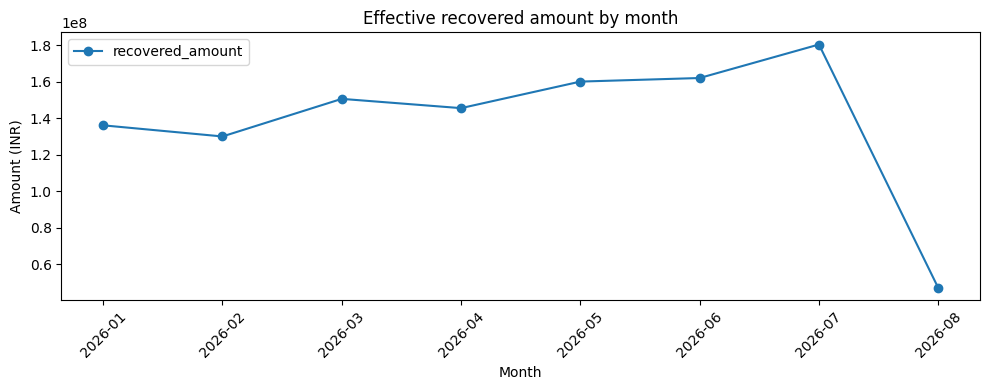

In [3]:
import matplotlib.pyplot as plt
ax=monthly.plot(x='month', y='recovered_amount', marker='o', figsize=(10,4), title='Effective recovered amount by month')
ax.set_ylabel('Amount (INR)'); ax.set_xlabel('Month'); plt.xticks(rotation=45); plt.tight_layout()

## 2. Segment mix

Compare recovered amount by risk segment. Do not interpret differences as causal effects: targeting is not randomized and account mix may differ.

In [4]:
seg=pd.read_csv(OUT/'segment_monthly_metrics.csv')
seg.pivot(index='month', columns='risk_segment', values='recovered_amount').fillna(0)

risk_segment,HIGH,LOW,MEDIUM,NPA
month,,,,
2026-01,34839069.44,32925648.48,34410964.29,34026176.95
2026-02,31787142.24,32319131.57,33277921.23,32715343.44
2026-03,36726512.75,38105529.54,36748330.02,39134913.57
2026-04,35150055.38,40576304.61,36662079.54,33243951.78
2026-05,42888525.60,39006010.16,38607363.55,39690259.60
2026-06,41960121.71,40026633.09,42064734.70,38097891.46
2026-07,43159777.97,48456573.62,46518170.67,42394225.27
2026-08,13330659.19,10106795.74,10352096.21,13257778.09


## 3. Data quality checks

In [5]:
qa.sort_values(['dataset','metric']).head(40)

,dataset,metric,value
1,account_status_history,duplicate_full_rows,0.0
2,account_status_history,missing_cells,0.0
0,account_status_history,raw_rows,60000.0
61,accounts,canonical_account_ids,30000.0
4,accounts,duplicate_full_rows,0.0
5,accounts,missing_cells,455.0
3,accounts,raw_rows,30000.0
7,agent_sessions,duplicate_full_rows,0.0
8,agent_sessions,missing_cells,0.0
6,agent_sessions,raw_rows,15000.0


## 4. Targeting and campaign association (not causal)

A payment within seven days after a targeting event is only a temporal association. Accounts may receive multiple touches and are not randomly assigned. Do not label this as campaign-attributed recovery.

In [6]:
targeting = pd.read_csv(OUT/'targeting_descriptive_association.csv')
targeting.sort_values('observed_conversion_rate_pct', ascending=False)

,recommended_channel,targets,accounts,targets_with_payment_7d,observed_payment_amount_7d,observed_conversion_rate_pct,interpretation
2,VOICE,11202,9393,190,14681127.05,1.696126,Descriptive only; no randomized holdout or cau...
1,SMS,11221,9360,175,12611349.25,1.559576,Descriptive only; no randomized holdout or cau...
3,WHATSAPP,11212,9363,169,12494952.03,1.507314,Descriptive only; no randomized holdout or cau...
0,FIELD,11365,9493,163,12760497.73,1.434228,Descriptive only; no randomized holdout or cau...


## 5. Mix-adjusted descriptive metric

This standardizes amount per account to fixed risk-segment weights. It is a robustness check on portfolio composition, not a recovery rate and not a causal estimate.

In [7]:
mix = pd.read_csv(OUT/'mix_adjusted_descriptive_metrics.csv')
monthly.merge(mix, on='month', how='left')

,month,recovered_amount,successful_transactions,transactions,unique_payers,mom_growth_pct,partial_month,mix_standardized_amount_per_account,observed_total_recovered_amount,interpretation
0,2026-01,1.362019e+08,1787,2577,1742,NaN,False,4540.061972,1.362019e+08,Mix-standardized amount per account using fixe...
1,2026-02,1.300995e+08,1735,2412,1672,-4.480351,False,4336.651283,1.300995e+08,Mix-standardized amount per account using fixe...
2,2026-03,1.507153e+08,2026,2865,1958,15.846134,False,5023.842863,1.507153e+08,Mix-standardized amount per account using fixe...
3,2026-04,1.456324e+08,2000,2906,1930,-3.372514,False,4854.413044,1.456324e+08,Mix-standardized amount per account using fixe...
4,2026-05,1.601922e+08,2136,3049,2055,9.997616,False,5339.738630,1.601922e+08,Mix-standardized amount per account using fixe...
5,2026-06,1.621494e+08,2183,3098,2118,1.221796,False,5404.979365,1.621494e+08,Mix-standardized amount per account using fixe...
6,2026-07,1.805287e+08,2360,3371,2259,11.334836,False,6017.624918,1.805287e+08,Mix-standardized amount per account using fixe...
7,2026-08,4.704733e+07,613,911,605,-73.939148,True,1568.244308,4.704733e+07,Mix-standardized amount per account using fixe...


## 6. Decision

The “11% month-on-month recovery” claim is not validated. The input does not contain approximately 12 complete months or historical month-opening eligible balance. Any ROI or strategy lift needs a controlled experiment and intervention cost data.

## 7. Cleaning impact and acceptance checks

The following tables are generated by the pipeline from raw and canonical outputs. Row and amount differences quantify the impact of the selected rules; they are **not automatically a count of invalid or fraudulent records**. REVIEW statuses require owner policy decisions.

In [8]:
impact = pd.read_csv(OUT/'cleaning_impact_summary.csv')
acceptance = pd.read_csv(OUT/'data_quality_acceptance_checks.csv')
print('Cleaning impact')
display(impact)
print('Acceptance checks by status')
display(acceptance.groupby(['severity','status']).size().rename('checks').reset_index())
display(acceptance[['check_id','severity','check','observed','threshold','status','action']])

Cleaning impact


,measure,value,interpretation
0,Raw payment rows,2.550000e+04,Rows before deduplication
1,After payment_id deduplication,2.500000e+04,Unique payment IDs; some IDs may have status/e...
2,Canonical transaction-reference events,2.118900e+04,Latest canonical event per reference; missing ...
3,Rows removed between raw and canonical,4.311000e+03,Net reduction; not every removed row is necess...
4,Raw SUCCESS amount before canonicalization (INR),1.341486e+09,"Inflated/uncanonicalized comparison, not an ap..."
5,Canonical effective SUCCESS cash (INR),1.112567e+09,Only final canonical SUCCESS amounts contribute
6,Raw SUCCESS minus canonical cash (INR),2.289192e+08,Difference caused by event/reference/status ca...
7,Canonical event reduction (%),1.691000e+01,Reduction relative to raw payment rows
8,Cash amount reduction (%),1.706000e+01,Comparison of raw SUCCESS rows vs canonical ef...
9,Golden account-month rows,2.400000e+05,Account × observed month spine


Acceptance checks by status


,severity,status,checks
0,CRITICAL,PASS,8
1,HIGH,PASS,6


,check_id,severity,check,observed,threshold,status,action
0,PAY-001,CRITICAL,Canonical transaction key unique,0.0,0 duplicates,PASS,Block release if failed
1,PAY-002,CRITICAL,Non-success cash excluded,0.0,₹0,PASS,Block release if failed
2,PAY-003,HIGH,Raw payment ID missing count,0.0,0,PASS,Quarantine rows with missing IDs
3,PAY-004,HIGH,Unrecognized raw payment statuses,0.0,0 or approved mapping,PASS,Map or quarantine unknown statuses
4,PAY-005,HIGH,Negative or unparseable raw payment amounts,0.0,0 or approved reversal policy,PASS,Reconcile to payment ledger
5,GOLD-001,CRITICAL,Unique account-month key,0.0,0 duplicates,PASS,Block release if failed
6,GOLD-002,HIGH,Golden account coverage vs canonical accounts,30000.0,30000 canonical accounts,PASS,Investigate missing accounts
7,GOLD-003,HIGH,Historical denominator clearly flagged,0.0,0 missing warnings,PASS,Keep rate claims blocked until historical bala...
8,DQ-001,HIGH,Payment account IDs resolve to canonical accounts,0.0,0 or documented exception,PASS,Resolve or quarantine orphan rows
9,DQ-002,CRITICAL,Monthly recovered cash reconciles to canonical...,0.0,₹0 difference,PASS,Block release if failed


## 8. Investment scenario model (not causal evidence)

Better borrower targeting is the leading investment **hypothesis to test**, not a proven observational winner. The ROI outputs are a transparent sensitivity model based on a 70% targetable-cash share, 5%/10%/15% lift assumptions, an 85% realization factor, and ₹10 Cr program cost. Replace these with Finance-approved values and randomized pilot estimates before capital release.

In [9]:
roi = pd.read_csv(OUT/'investment_roi_scenarios.csv')
display(roi[['scenario','targetable_share_assumption_pct','incremental_lift_assumption_pct','incremental_gross_recovery_inr','realized_economic_benefit_inr','net_benefit_after_investment_inr','planning_roi_pct','break_even_gross_incremental_recovery_inr','classification']])

,scenario,targetable_share_assumption_pct,incremental_lift_assumption_pct,incremental_gross_recovery_inr,realized_economic_benefit_inr,net_benefit_after_investment_inr,planning_roi_pct,break_even_gross_incremental_recovery_inr,classification
0,Downside,70.0,5.0,6.393116e+07,5.434149e+07,-45658512.53,-45.66,1.176471e+08,ASSUMPTION-BASED SCENARIO; NOT MEASURED CAUSAL...
1,Base case,70.0,10.0,1.278623e+08,1.086830e+08,8682974.95,8.68,1.176471e+08,ASSUMPTION-BASED SCENARIO; NOT MEASURED CAUSAL...
2,Upside,70.0,15.0,1.917935e+08,1.630245e+08,63024462.42,63.02,1.176471e+08,ASSUMPTION-BASED SCENARIO; NOT MEASURED CAUSAL...


## 9. Counterfactual decision rule

Use account- or borrower-level randomized assignment, stratified by DPD, risk, loan type, balance band and prior contact. Primary outcome: 30-day net cash per eligible account after reversals/refunds. Analyze by intent-to-treat, report treatment-minus-control with a 95% confidence interval, include per-arm costs and customer guardrails, and scale only when the lower confidence bound on net benefit is positive. Numeric sample size is pending a valid outcome variance and minimum economically meaningful effect; the supplied observational data cannot establish causal lift.